In [ ]:
BTVN BÀI 1

[Nhiễu thấp (Standard = 30)] -> MSE: 976.16 | R2 Score: 0.9984
[Nhiễu trung bình (Standard = 150)] -> MSE: 24875.65 | R2 Score: 0.9612
[Nhiễu cực cao (Standard = 450)] -> MSE: 210968.58 | R2 Score: 0.8051


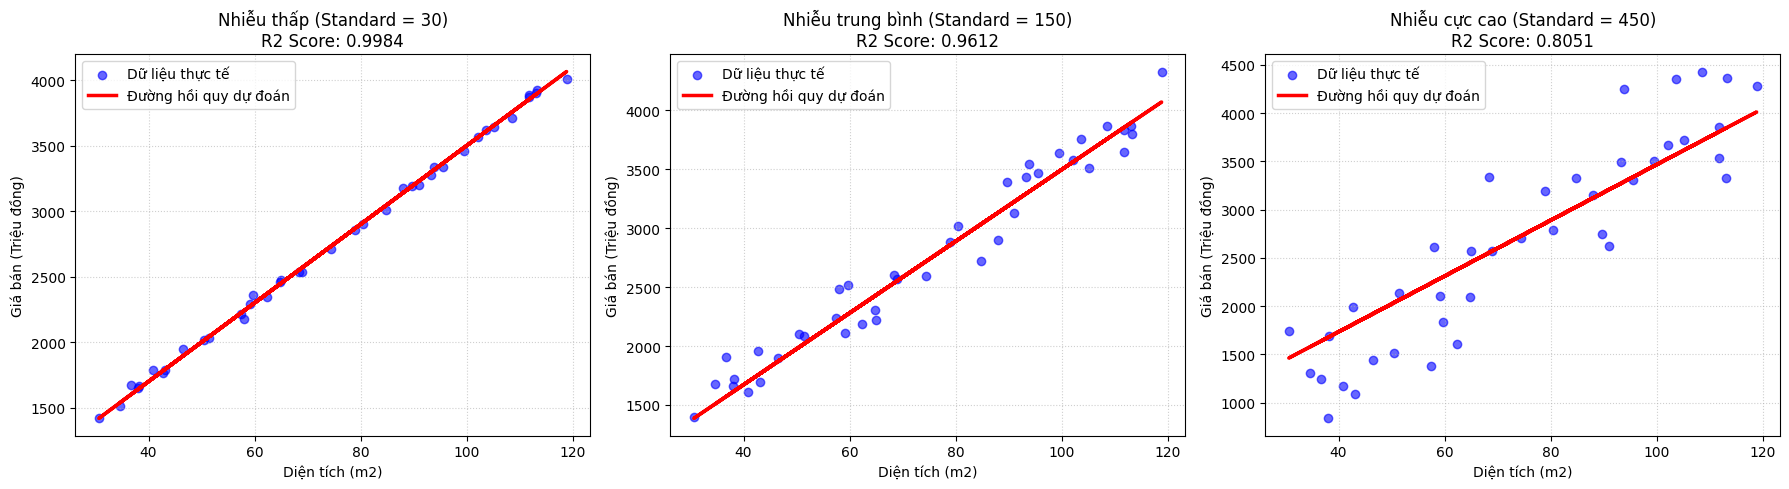

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Thiết lập sinh số ngẫu nhiên cố định
np.random.seed(42)
n_samples = 200

# Sinh biến độc lập X (Diện tích nhà từ 30m2 đến 120m2)
X = 30 + 90 * np.random.rand(n_samples, 1)

# Thiết lập 3 mức độ nhiễu khác nhau để thử nghiệm
noises = {
    'Nhiễu thấp (Standard = 30)': 30,
    'Nhiễu trung bình (Standard = 150)': 150,
    'Nhiễu cực cao (Standard = 450)': 450
}

plt.figure(figsize=(18, 5))

for i, (label, noise_level) in enumerate(noises.items(), 1):
    # Hàm sinh giá trị thực tế y kèm độ nhiễu tương ứng
    y = 500 + 30 * X + np.random.randn(n_samples, 1) * noise_level

    # Chia tập dữ liệu
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Huấn luyện mô hình
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Dự đoán
    y_pred = model.predict(X_test)

    # Đánh giá độ chính xác
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # In kết quả định lượng
    print(f"[{label}] -> MSE: {mse:.2f} | R2 Score: {r2:.4f}")

    # Vẽ biểu đồ trực quan hóa
    plt.subplot(1, 3, i)
    plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dữ liệu thực tế')
    plt.plot(X_test, y_pred, color='red', linewidth=2.5, label='Đường hồi quy dự đoán')
    plt.title(f"{label}\nR2 Score: {r2:.4f}")
    plt.xlabel('Diện tích (m2)')
    plt.ylabel('Giá bán (Triệu đồng)')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

BTVN BÀI 2

--- Ngưỡng quyết định: 0.3 ---
Độ chính xác (Accuracy): 0.78
Ma trận nhầm lẫn:
[[13  7]
 [ 2 18]]
------------------------------
--- Ngưỡng quyết định: 0.5 ---
Độ chính xác (Accuracy): 0.85
Ma trận nhầm lẫn:
[[17  3]
 [ 3 17]]
------------------------------
--- Ngưỡng quyết định: 0.7 ---
Độ chính xác (Accuracy): 0.85
Ma trận nhầm lẫn:
[[18  2]
 [ 4 16]]
------------------------------


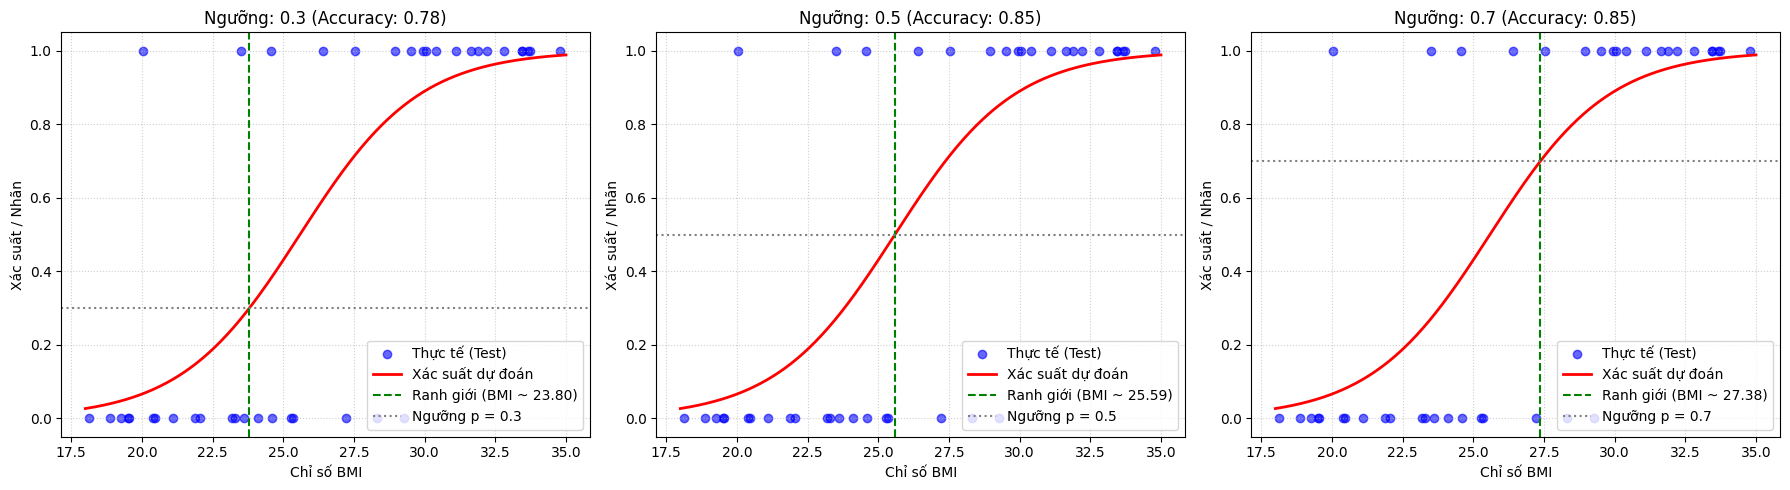

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tái sử dụng dữ liệu giả lập từ Bài 2 gốc
np.random.seed(42)
n_samples = 200
bmi = 18 + 17 * np.random.rand(n_samples, 1)
logits = 0.5 * (bmi - 26)
probabilities = 1 / (1 + np.exp(-logits))
mac_benh = (np.random.rand(n_samples, 1) < probabilities).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình Hồi quy Logistic
model_logistic = LogisticRegression()
model_logistic.fit(X_train, y_train)

# Lấy xác suất dự đoán mắc bệnh (lớp 1) trên tập kiểm tra
y_probs = model_logistic.predict_proba(X_test)[:, 1]

# 3. Thử nghiệm các ngưỡng phân loại khác nhau
thresholds = [0.3, 0.5, 0.7]
plt.figure(figsize=(18, 5))

for i, threshold in enumerate(thresholds, 1):
    # Dự đoán nhãn dựa trên ngưỡng tùy chỉnh thay vì mặc định 0.5
    y_pred_custom = (y_probs >= threshold).astype(int)

    # Đánh giá
    acc = accuracy_score(y_test, y_pred_custom)
    cm = confusion_matrix(y_test, y_pred_custom)

    print(f"--- Ngưỡng quyết định: {threshold} ---")
    print(f"Độ chính xác (Accuracy): {acc:.2f}")
    print("Ma trận nhầm lẫn:")
    print(cm)
    print("-" * 30)

    # 4. Vẽ biểu đồ trực quan hóa
    plt.subplot(1, 3, i)
    # Điểm thực tế
    plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Thực tế (Test)')

    # Đường cong Sigmoid
    X_curve = np.linspace(18, 35, 300).reshape(-1, 1)
    y_curve_prob = model_logistic.predict_proba(X_curve)[:, 1]
    plt.plot(X_curve, y_curve_prob, color='red', linewidth=2, label='Xác suất dự đoán')

    # Tính toán vị trí ranh giới phân loại theo ngưỡng mới:
    # logit = log(p / (1 - p)) = w * X + b => X_boundary = (log(p / (1 - p)) - b) / w
    w = model_logistic.coef_[0][0]
    b = model_logistic.intercept_[0]
    logit_threshold = np.log(threshold / (1 - threshold))
    custom_boundary = (logit_threshold - b) / w

    # Vẽ ranh giới phân loại mới
    plt.axvline(x=custom_boundary, color='green', linestyle='--',
                label=f'Ranh giới (BMI ~ {custom_boundary:.2f})')
    plt.axhline(y=threshold, color='gray', linestyle=':', label=f'Ngưỡng p = {threshold}')

    plt.title(f"Ngưỡng: {threshold} (Accuracy: {acc:.2f})")
    plt.xlabel('Chỉ số BMI')
    plt.ylabel('Xác suất / Nhãn')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

BTVN BÀI 3

==> Đã tải thành công tập dữ liệu California Housing!
Mô tả ngắn: .. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in...


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Mean Squared Error (MSE): 0.5559
R2 Score (Độ giải thích biến thiên): 0.5758


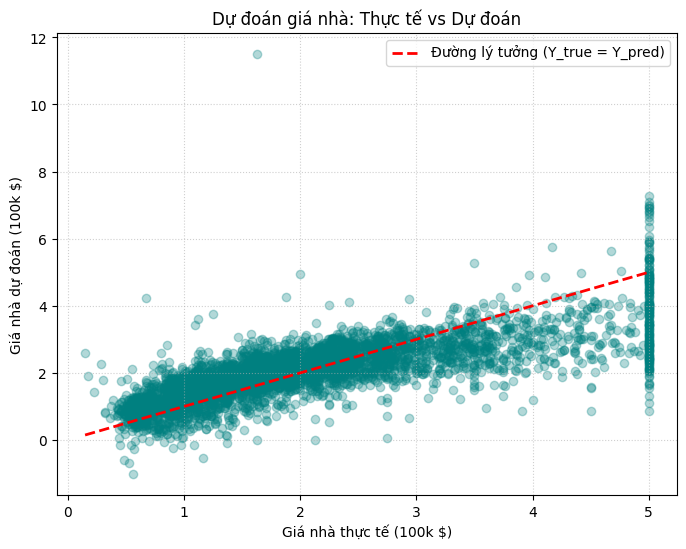

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu nhà đất California (Thay thế cho Boston Housing)
housing = fetch_california_housing(as_frame=True)
print("==> Đã tải thành công tập dữ liệu California Housing!")
print(f"Mô tả ngắn: {housing.DESCR[:280]}...")

# Chuyển đổi thành DataFrame để dễ quan sát
df_housing = housing.frame
display(df_housing.head())

# 2. Phân chia biến độc lập X và biến mục tiêu y (Giá nhà trung bình - MedHouseVal)
X_house = housing.data
y_house = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

# 3. Khởi tạo và huấn luyện mô hình Hồi quy tuyến tính
model_house = LinearRegression()
model_house.fit(X_train, y_train)

# 4. Dự đoán trên tập kiểm tra
y_pred = model_house.predict(X_test)

# 5. Tính toán các chỉ số đánh giá
mse_val = mean_squared_error(y_test, y_pred)
r2_val = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Mean Squared Error (MSE): {mse_val:.4f}")
print(f"R2 Score (Độ giải thích biến thiên): {r2_val:.4f}")

# 6. Biểu đồ trực quan hóa giá trị thực tế vs giá trị dự đoán
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='teal')

# Vẽ đường phân tuyến lý tưởng y = x
ideal_line = np.linspace(y_test.min(), y_test.max(), 100)
plt.plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2, label='Đường lý tưởng (Y_true = Y_pred)')

plt.title('Dự đoán giá nhà: Thực tế vs Dự đoán')
plt.xlabel('Giá nhà thực tế (100k $)')
plt.ylabel('Giá nhà dự đoán (100k $)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()